# Examen ICCD753 Recuperación de Información

## 1. Objetivo

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (*qrels*) del corpus.

## 2. Corpus asignado

Cada estudiante recibirá un conjunto de datos. Todos contienen documentos, consultas y qrels. Se utilizarán los identificadores originales de los documentos para que los resultados puedan evaluarse.

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| NFCorpus | [BeIR/nfcorpus](https://huggingface.co/datasets/BeIR/nfcorpus) | [BeIR/nfcorpus-qrels](https://huggingface.co/datasets/BeIR/nfcorpus-qrels) |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |

## 3. Requisitos del sistema

### 3.1. Preparación e indexación

El sistema deberá:

1. Cargar e indexar los documentos del corpus asignado.
2. Aplicar y documentar las decisiones de preprocesamiento: tokenización, normalización, eliminación de stopwords y stemming o lematización.
3. Construir un vocabulario y un índice invertido que permita recuperar documentos.
4. Conservar la relación entre cada documento indexado y su identificador original.

La unidad de evaluación será el documento original, porque los qrels relacionan consultas con identificadores de documentos. No se debe dividir el texto en fragmentos.

### 3.2. Modelos de recuperación

Para cualquier consulta de texto, el sistema deberá producir dos rankings independientes:

- TF-IDF con similitud coseno.
- BM25.

Cada ranking deberá ordenar los documentos por puntuación de relevancia y permitir solicitar los primeros `k` resultados.

### 3.3. Servicio web

El sistema deberá estar publicado en internet y ofrecer, como mínimo, los siguientes endpoints:

**Comprobación de disponibilidad**

```http
GET /health
```

**Búsqueda**

```http
POST /search
Content-Type: application/json
```

Ejemplo de solicitud:

```json
{
  "query": "texto de la consulta",
  "model": "bm25",
  "top_k": 10
}
```

El campo `model` deberá aceptar `bm25` y `tfidf`. Una respuesta tendrá esta estructura:

```json
{
  "model": "bm25",
  "results": [
    {
      "rank": 1,
      "document_id": "identificador_original",
      "score": 8.42,
      "title": "Título, si está disponible",
      "snippet": "Fragmento del documento recuperado"
    }
  ]
}
```

Los resultados deberán estar ordenados de mayor a menor puntuación, no contener documentos duplicados y respetar el valor solicitado de `top_k`. El servicio debe aceptar consultas que el estudiante no conozca de antemano.

## 4. Evaluación de la recuperación

Cada estudiante debe evaluar ambos modelos con consultas de la partición `test` y sus qrels. Presentará, como mínimo:

- Precision@10.
- Recall@10.
- NDCG@10.
- Una comparación de los resultados de TF-IDF y BM25.

En el Jupyter Notebook se deberá indicar qué consultas se utilizaron y permitir reproducir los cálculos. La evaluación del docente podrá utilizar otras consultas del mismo conjunto.

## 5. Prueba del docente

El docente accederá a la URL entregada y realizará solicitudes desde un cliente de web service para comprobar:

1. La disponibilidad del servicio.
2. El funcionamiento de TF-IDF y BM25.
3. El formato, orden y validez de los resultados.
4. La correspondencia de los `document_id` con el corpus y los qrels.
5. La respuesta ante consultas no incluidas en los ejemplos de entrega.

## 6. Entregables

Cada estudiante entregará:

1. La URL pública del servicio web, accesible durante el período de revisión.
2. El código en Jupyter Notebook con los resultados de la ejecución de cada bloque de código, incluyendo los resultados de las métricas de evaluación de los modelos de recuperación.

Se evaluará que ambos modelos funcionen correctamente y que cada estudiante interprete sus resultados.

-------

### Carga de NFCorpus, preprocesamiento e índice invertido

Para ejecutar el cuaderno, instalamos `snowballstemmer==3.0.1` en el entorno del kernel y habilitamos el acceso a internet para descargar NFCorpus desde BEIR. El código de búsqueda y de la API está incluido en las celdas.

Cada documento se indexa completo uniendo su título, si existe, y su texto con un espacio. Se aplica normalización Unicode NFKC y luego `casefold()` para unificar mayúsculas y minúsculas. La expresión regular `[^\W_]+` extrae secuencias de letras y números Unicode, usa la puntuación y los guiones bajos como separadores y conserva los números. Antes del stemming se eliminan únicamente los tokens que coinciden exactamente con la lista fija en inglés `STOPWORDS` de la celda, con términos como `the`, `and` y `of`. Se conservan las negaciones `no` y `not` dado que pueden ser relevantes para las consultas, a cada token restante se le aplica el stemmer inglés de Snowball. Las consultas pasan por la misma función. El índice conserva el ID original, la frecuencia de cada término y la longitud de cada documento en tokens procesados.

La celda descarga el archivo oficial de BEIR, verifica que los juicios de relevancia correspondan a documentos y consultas existentes, y construye el vocabulario, el índice invertido y las estadísticas que usan ambos modelos.

In [1]:
import csv
import json
import math
import os
import re
import unicodedata
from collections import Counter, defaultdict
from functools import lru_cache
from io import BytesIO, TextIOWrapper
from urllib.request import urlopen
from zipfile import ZipFile

from snowballstemmer import stemmer


CORPUS = os.getenv("BEIR_CORPUS", "nfcorpus")
MODELS = ("tfidf", "bm25")
STOPWORDS = frozenset("""
    a an and are as at be been being but by can could did do does for from
    had has have he her hers him his how i if in into is it its may me might
    more most my of on or our ours she should so than that the their theirs
    them then there these they this those through to under up us was we were
    what when where which who will with would you your yours
""".split())
TOKEN_PATTERN = re.compile(r"[^\W_]+", re.UNICODE)


@lru_cache(maxsize=65536)
def english_stem(token):
    return stemmer("english").stemWord(token)


def tokenize(text):
    normalized = unicodedata.normalize("NFKC", text).casefold()
    return [
        english_stem(token)
        for token in TOKEN_PATTERN.findall(normalized)
        if token not in STOPWORDS
    ]


@lru_cache(maxsize=2)
def load_beir(corpus):
    if corpus not in ("scifact", "nfcorpus"):
        raise ValueError("BEIR_CORPUS debe ser scifact o nfcorpus")
    base_url = "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets"
    with urlopen(f"{base_url}/{corpus}.zip", timeout=90) as response:
        archive = BytesIO(response.read())
    with ZipFile(archive) as data:
        with data.open(f"{corpus}/corpus.jsonl") as source:
            documents = {str(row["_id"]): row for row in map(json.loads, source)}
        with data.open(f"{corpus}/queries.jsonl") as source:
            queries = {str(row["_id"]): row["text"] for row in map(json.loads, source)}
        qrels = defaultdict(dict)
        with TextIOWrapper(data.open(f"{corpus}/qrels/test.tsv"), encoding="utf-8") as source:
            for row in csv.DictReader(source, delimiter="\t"):
                qrels[row["query-id"]][row["corpus-id"]] = int(row["score"])
    return documents, queries, dict(qrels)



class SearchIndex:
    def __init__(self, documents):
        self.documents = documents
        self.postings = defaultdict(dict)
        self.lengths = {}
        for document_id, doc in documents.items():
            counts = Counter(tokenize(f"{doc.get('title') or ''} {doc['text']}"))
            self.lengths[document_id] = counts.total()
            for term, frequency in counts.items():
                self.postings[term][document_id] = frequency

        self.vocabulary = frozenset(self.postings)
        total = len(documents)
        self.average_length = sum(self.lengths.values()) / total
        self.tfidf_idf = {}
        self.bm25_idf = {}
        squared_norms = defaultdict(float)
        for term, posting in self.postings.items():
            df = len(posting)
            idf = math.log((total + 1) / (df + 1)) + 1
            self.tfidf_idf[term] = idf
            self.bm25_idf[term] = math.log1p((total - df + 0.5) / (df + 0.5))
            for document_id, frequency in posting.items():
                squared_norms[document_id] += ((1 + math.log(frequency)) * idf) ** 2
        self.norms = {key: math.sqrt(value) for key, value in squared_norms.items()}

    def rank(self, query, model, top_k):
        if model == "tfidf":
            return rank_tfidf(self, query, top_k)
        if model == "bm25":
            return rank_bm25(self, query, top_k)
        raise ValueError("Modelo desconocido")

    def search(self, query, model, top_k):
        results = []
        for rank, (document_id, score) in enumerate(self.rank(query, model, top_k), 1):
            doc = self.documents[document_id]
            text = " ".join(doc["text"].split())
            results.append({
                "rank": rank,
                "document_id": document_id,
                "score": score,
                "title": doc.get("title") or "",
                "snippet": text[:240] + ("…" if len(text) > 240 else ""),
            })
        return {"model": model, "results": results}



corpus = 'nfcorpus'
documents, queries, qrels = load_beir(corpus)
assert qrels.keys() <= queries.keys()
assert all(judgments.keys() <= documents.keys() for judgments in qrels.values())
index = SearchIndex(documents)

print(f'Corpus {corpus} | documentos {len(documents)} | vocabulario {len(index.vocabulary)}')
print(f'Longitud media {index.average_length:.2f} tokens')
print('Ejemplo de preprocesamiento', tokenize('The effects of processed foods on health'))

Corpus nfcorpus | documentos 3633 | vocabulario 19116
Longitud media 171.40 tokens
Ejemplo de preprocesamiento ['effect', 'process', 'food', 'health']


## TF-IDF con similitud coseno

La función tokeniza la consulta y calcula el peso de cada término del vocabulario con TF sublineal, 1 + log(tf), e IDF suavizada, log((N + 1) / (df + 1)) + 1. Recorre el índice invertido para acumular el producto escalar y divide por las normas de la consulta y del documento. Los empates se resuelven por ID.

In [2]:
def rank_tfidf(index, query, top_k=10):
    terms = Counter(tokenize(query))
    weights = {
        term: (1 + math.log(frequency)) * index.tfidf_idf[term]
        for term, frequency in terms.items()
        if term in index.vocabulary
    }
    query_norm = math.sqrt(sum(weight ** 2 for weight in weights.values()))
    scores = defaultdict(float)
    for term, query_weight in weights.items():
        for doc_id, frequency in index.postings[term].items():
            doc_weight = (1 + math.log(frequency)) * index.tfidf_idf[term]
            scores[doc_id] += query_weight * doc_weight
    for doc_id in scores:
        scores[doc_id] /= index.norms[doc_id] * query_norm
    return sorted(scores.items(), key=lambda item: (-item[1], item[0]))[:top_k]

example_query = 'dietary fiber and colon health'
print('TF-IDF', rank_tfidf(index, example_query, top_k=3))

TF-IDF [('MED-2578', 0.3178939674305644), ('MED-1234', 0.26856404875159173), ('MED-3136', 0.2569791647029023)]


## BM25

La función acumula la contribución de cada término distinto de la consulta. Usa k₁ = 1.2 y b = 0.75, pondera por la IDF de BM25 y ajusta la frecuencia del término por la longitud del documento respecto a la media. Devuelve los primeros resultados en orden de puntuación y resuelve los empates por ID.

In [3]:
def rank_bm25(index, query, top_k=10):
    terms = dict.fromkeys(tokenize(query))
    scores = defaultdict(float)
    k1, b = 1.2, 0.75
    for term in terms:
        if term not in index.vocabulary:
            continue
        for doc_id, frequency in index.postings[term].items():
            length_ratio = index.lengths[doc_id] / index.average_length
            denominator = frequency + k1 * (1 - b + b * length_ratio)
            scores[doc_id] += index.bm25_idf[term] * frequency * (k1 + 1) / denominator
    return sorted(scores.items(), key=lambda item: (-item[1], item[0]))[:top_k]

print('BM25', rank_bm25(index, example_query, top_k=3))

BM25 [('MED-2578', 13.94585406616142), ('MED-3136', 12.863075673728645), ('MED-2544', 12.814141294422726)]


### Cálculo de las métricas

Se ejecuta cada consulta de `test` con TF-IDF y BM25. Los primeros diez resultados se contrastan con los qrels para calcular Precision@10, Recall@10 y NDCG@10 por consulta. La salida muestra los IDs evaluados y el promedio de cada métrica por modelo. La evaluación usa el mismo método de ranking que emplea la API.

In [4]:
from math import log2
from statistics import mean

def metrics_at_10(ranking, judgments):
    grades = [judgments.get(doc_id, 0) for doc_id, _ in ranking[:10]]
    relevant = sum(grade > 0 for grade in judgments.values())
    hits = sum(grade > 0 for grade in grades)
    dcg = sum(grade / log2(rank + 1) for rank, grade in enumerate(grades, 1))
    ideal = sorted(judgments.values(), reverse=True)[:10]
    idcg = sum(grade / log2(rank + 1) for rank, grade in enumerate(ideal, 1))
    return hits / 10, hits / relevant if relevant else 0, dcg / idcg if idcg else 0

test_ids = sorted(qrels)
print(f'{len(test_ids)} consultas evaluadas')
print(', '.join(test_ids))
for qid in test_ids[:3]:
    print(qid, queries[qid])

metric_names = ('Precision@10', 'Recall@10', 'NDCG@10')
averages = {}
for model in MODELS:
    per_query = [
        metrics_at_10(index.rank(queries[qid], model, 10), qrels[qid])
        for qid in test_ids
    ]
    averages[model] = tuple(mean(values) for values in zip(*per_query))

print()
print(f"{'Modelo':<8}" + ''.join(f'{name:>16}' for name in metric_names))
for model, values in averages.items():
    print(f'{model:<8}' + ''.join(f'{value:>16.4f}' for value in values))

323 consultas evaluadas
PLAIN-1008, PLAIN-1018, PLAIN-102, PLAIN-1028, PLAIN-1039, PLAIN-1050, PLAIN-1066, PLAIN-1088, PLAIN-1098, PLAIN-1109, PLAIN-1119, PLAIN-112, PLAIN-1130, PLAIN-1141, PLAIN-1151, PLAIN-1161, PLAIN-1172, PLAIN-1183, PLAIN-1193, PLAIN-12, PLAIN-1203, PLAIN-1214, PLAIN-1225, PLAIN-123, PLAIN-1236, PLAIN-1249, PLAIN-1262, PLAIN-1275, PLAIN-1288, PLAIN-1299, PLAIN-1309, PLAIN-1320, PLAIN-133, PLAIN-1331, PLAIN-1342, PLAIN-1353, PLAIN-1363, PLAIN-1374, PLAIN-1387, PLAIN-1398, PLAIN-1409, PLAIN-1419, PLAIN-1429, PLAIN-143, PLAIN-1441, PLAIN-1453, PLAIN-1463, PLAIN-1473, PLAIN-1485, PLAIN-1496, PLAIN-1506, PLAIN-1516, PLAIN-1527, PLAIN-153, PLAIN-1537, PLAIN-1547, PLAIN-1557, PLAIN-1568, PLAIN-1579, PLAIN-1590, PLAIN-1601, PLAIN-1611, PLAIN-1621, PLAIN-1635, PLAIN-1645, PLAIN-165, PLAIN-1656, PLAIN-1667, PLAIN-1679, PLAIN-1690, PLAIN-1700, PLAIN-1710, PLAIN-1721, PLAIN-1731, PLAIN-1741, PLAIN-175, PLAIN-1752, PLAIN-1762, PLAIN-1772, PLAIN-1784, PLAIN-1794, PLAIN-1805, PL

### Comparación de los modelos

Se resta el promedio de TF-IDF al de BM25 para cada métrica. El signo identifica qué modelo obtuvo el valor más alto y la magnitud se expresa en puntos porcentuales. La comparación muestra en qué aspecto de la recuperación destaca cada modelo.

La gráfica de barras agrupadas muestra los promedios de Precision@10, Recall@10 y NDCG@10 para ambos modelos. Para volver a generarla, instala `matplotlib` en el entorno del kernel.

BM25 supera al otro modelo por 0.59 puntos en Precision@10.
TF-IDF supera al otro modelo por 0.06 puntos en Recall@10.
BM25 supera al otro modelo por 0.49 puntos en NDCG@10.
Precision@10 mide cuántos de los primeros diez resultados son relevantes.
Recall@10 indica cuánto del conjunto relevante se recuperó en esos diez lugares.
NDCG@10 favorece los documentos de mayor relevancia en las primeras posiciones.


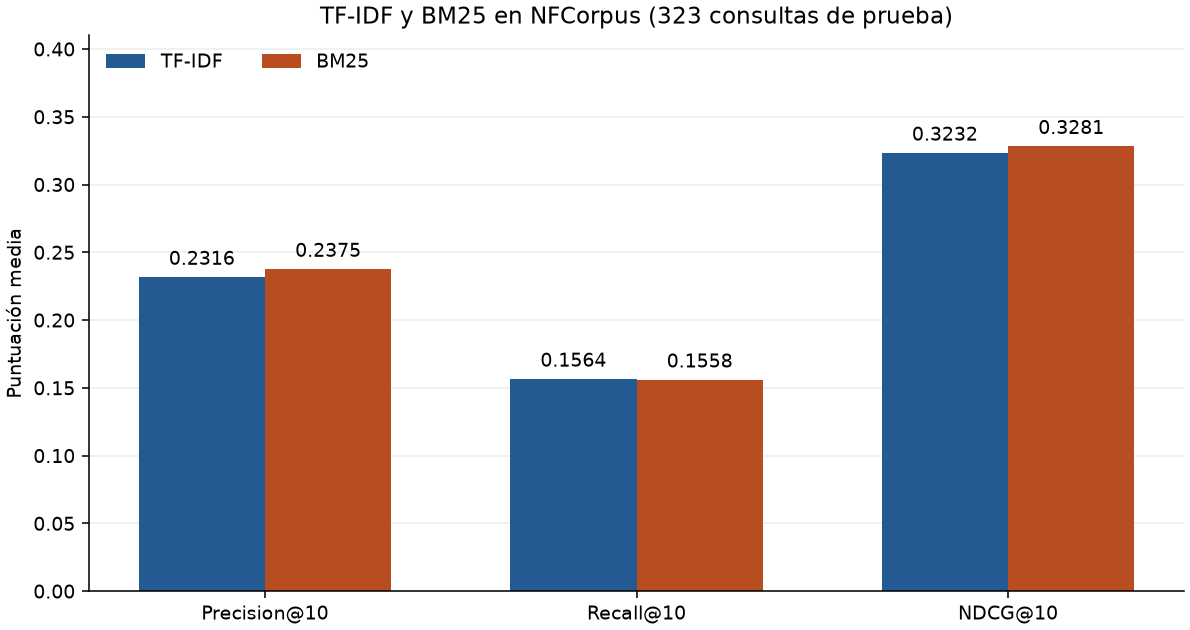

In [5]:
for name, tfidf, bm25 in zip(metric_names, averages['tfidf'], averages['bm25']):
    difference = (bm25 - tfidf) * 100
    if abs(difference) < 0.005:
        print(f'{name} registra un empate a la precisión mostrada.')
    else:
        winner = 'BM25' if difference > 0 else 'TF-IDF'
        print(f'{winner} supera al otro modelo por {abs(difference):.2f} puntos en {name}.')

print('Precision@10 mide cuántos de los primeros diez resultados son relevantes.')
print('Recall@10 indica cuánto del conjunto relevante se recuperó en esos diez lugares.')
print('NDCG@10 favorece los documentos de mayor relevancia en las primeras posiciones.')

import matplotlib.pyplot as plt

positions = range(len(metric_names))
width = 0.34
figure, ax = plt.subplots(figsize=(8.5, 4.5), layout='constrained')
models = [
    ('tfidf', 'TF-IDF', -width / 2, '#235A91'),
    ('bm25', 'BM25', width / 2, '#B84D22'),
]
for model, label, offset, color in models:
    bars = ax.bar([position + offset for position in positions], averages[model],
                  width, label=label, color=color)
    ax.bar_label(bars, fmt='%.4f', padding=4)

ax.set_xticks(positions, metric_names)
ax.set_ylabel('Puntuación media')
ax.set_ylim(0, max(max(values) for values in averages.values()) * 1.25)
ax.set_title(f'TF-IDF y BM25 en NFCorpus ({len(test_ids)} consultas de prueba)')
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.22)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', ncols=2, frameon=False)
plt.show()


## Implementación del servicio web

`create_app` define `GET /health` y `POST /search`, valida las solicitudes y devuelve respuestas JSON. `production_app` carga NFCorpus y construye el índice al arrancar. La función `serve_local` puede iniciarse manualmente desde el cuaderno. La prueba posterior usa un servidor temporal y lo cierra al terminar.

In [6]:
def create_app(index, corpus):
    def application(environ, start_response):
        def respond(status, payload):
            body = json.dumps(payload, ensure_ascii=False).encode("utf-8")
            start_response(status, [
                ("Content-Type", "application/json; charset=utf-8"),
                ("Content-Length", str(len(body))),
            ])
            return [body]

        path = environ["PATH_INFO"]
        method = environ["REQUEST_METHOD"]
        if path == "/health" and method == "GET":
            return respond("200 OK", {
                "status": "ok", "corpus": corpus, "documents": len(index.documents),
            })
        if path != "/search" or method != "POST":
            return respond("404 Not Found", {"error": "Ruta o método desconocido"})
        try:
            length = int(environ.get("CONTENT_LENGTH") or 0)
            if length > 65536:
                return respond("413 Payload Too Large", {"error": "Solicitud demasiado grande"})
            if length <= 0:
                raise ValueError
            request = json.loads(environ["wsgi.input"].read(length))
        except (ValueError, RecursionError):
            return respond("400 Bad Request", {"error": "Envía un objeto JSON válido"})
        if not isinstance(request, dict):
            return respond("400 Bad Request", {"error": "Envía un objeto JSON"})
        query = request.get("query")
        model = request.get("model")
        top_k = request.get("top_k", 10)
        if not isinstance(query, str) or not query.strip():
            return respond("400 Bad Request", {"error": "query debe ser texto no vacío"})
        if model not in MODELS:
            return respond("400 Bad Request", {"error": "model debe ser bm25 o tfidf"})
        if type(top_k) is not int or top_k < 1:
            return respond("400 Bad Request", {"error": "top_k debe ser un entero positivo"})
        return respond("200 OK", index.search(query, model, min(top_k, len(index.documents))))

    return application


def production_app():
    documents, _, _ = load_beir(CORPUS)
    return create_app(SearchIndex(documents), CORPUS)


def serve_local():
    from wsgiref.simple_server import make_server

    with make_server("127.0.0.1", 8000, production_app()) as server:
        print("http://127.0.0.1:8000/health", flush=True)
        server.serve_forever()


print("API definida con GET /health y POST /search.")

API definida con GET /health y POST /search.


## Prueba de la API

Se inicia un servidor local temporal con el índice construido arriba. La consulta de prueba se define por separado de la evaluación. Se comprueban los dos modelos, los IDs, el orden, el límite solicitado y una solicitud inválida.

### Verificación de los endpoints

Se inicia un servidor temporal y se consulta `GET /health` para comprobar que NFCorpus esté cargado. Luego se envía la misma consulta a `POST /search` con ambos modelos y se verifican los IDs, el orden de las puntuaciones y el límite de tres resultados. Una solicitud inválida debe devolver HTTP 400.

In [7]:
import json
from threading import Thread
from urllib.error import HTTPError
from urllib.request import Request, urlopen
from wsgiref.simple_server import WSGIRequestHandler, make_server

class QuietHandler(WSGIRequestHandler):
    def log_message(self, format, *args):
        pass

with make_server('127.0.0.1', 0, create_app(index, corpus), handler_class=QuietHandler) as server:
    base_url = f'http://127.0.0.1:{server.server_port}'
    thread = Thread(target=server.serve_forever, daemon=True)
    thread.start()
    try:
        with urlopen(f'{base_url}/health', timeout=10) as response:
            health = json.load(response)
        assert health == {'status': 'ok', 'corpus': corpus, 'documents': len(documents)}
        print(health)
        for model in MODELS:
            body = {'query': 'dietary fiber and colon health', 'model': model, 'top_k': 3}
            request = Request(f'{base_url}/search', data=json.dumps(body).encode(),
                              headers={'Content-Type': 'application/json'}, method='POST')
            with urlopen(request, timeout=10) as response:
                payload = json.load(response)
            results = payload['results']
            assert payload['model'] == model and len(results) == 3
            ids = [row['document_id'] for row in results]
            scores = [row['score'] for row in results]
            assert len(set(ids)) == 3 and all(doc_id in documents for doc_id in ids)
            assert [row['rank'] for row in results] == [1, 2, 3]
            assert scores == sorted(scores, reverse=True)
            assert all(row['snippet'] and isinstance(row['title'], str) for row in results)
            print(model, list(zip(ids, [round(score, 4) for score in scores])))
        invalid = Request(f'{base_url}/search', data=b'{}', method='POST')
        try:
            urlopen(invalid, timeout=10).close()
        except HTTPError as error:
            assert error.code == 400
            print('Solicitud inválida rechazada con HTTP 400')
        else:
            raise AssertionError('Se esperaba HTTP 400')
    finally:
        server.shutdown()
        thread.join()

{'status': 'ok', 'corpus': 'nfcorpus', 'documents': 3633}
tfidf [('MED-2578', 0.3179), ('MED-1234', 0.2686), ('MED-3136', 0.257)]
bm25 [('MED-2578', 13.9459), ('MED-3136', 12.8631), ('MED-2544', 12.8141)]
Solicitud inválida rechazada con HTTP 400


## Publicación y prueba con Postman

**URL pública de la entrega** · [nfcorpus-buscador.onrender.com](https://nfcorpus-buscador.onrender.com)

- Disponibilidad mediante `GET /health`. [Endpoint de disponibilidad](https://nfcorpus-buscador.onrender.com/health)
- Búsqueda mediante `POST https://nfcorpus-buscador.onrender.com/search`.

![TF-IDF](tfidf.png)

![Health](health.png)

![BM25](bm25.png)